<a href="https://colab.research.google.com/github/poornan2207/ML_LAB_2026-27/blob/main/Breastcancer_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset loaded successfully!
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst texture  worst perimeter 

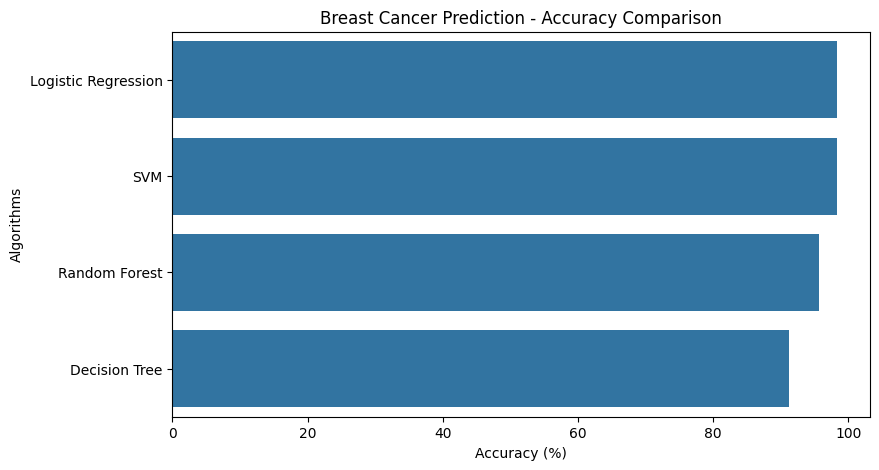

Best Algorithm: Logistic Regression
\nClassification Report:
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



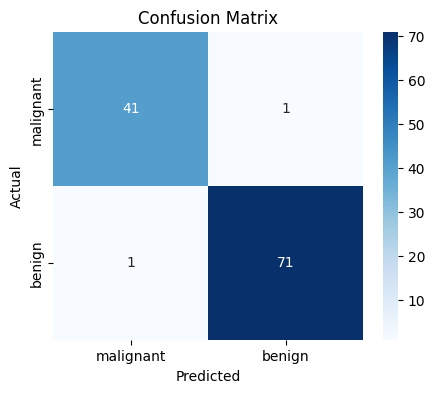

Model Prediction: Benign
\nNote: This is an educational model prediction, not a medical diagnosis.


In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.datasets import load_breast_cancer
data = load_breast_cancer()

df = pd.DataFrame(data.data, columns=data.feature_names)
df["Diagnosis"] = data.target

print("Dataset loaded successfully!")
print(df.head())
print("Dataset Shape:", df.shape)
print("Dataset Information:")
print(df.info())

print("\\nMissing Values:")
print(df.isnull().sum())

X = df.drop("Diagnosis", axis=1)
y = df["Diagnosis"]

print("\\nFeatures:", X.shape)
print("Target:", y.shape)

print("\\nTarget Values:")
print("0 = Malignant")
print("1 = Benign")
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)
numeric_features = X.select_dtypes(include=["int64", "float64"]).columns

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features)
])

print("Data preprocessing completed!")
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "SVM": SVC()
}

results = []
trained_models = {}

for name, model in models.items():

    pipeline = Pipeline(steps=[
        ("preprocessing", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)

    accuracy = accuracy_score(y_test, predictions)

    results.append({
        "Algorithm": name,
        "Accuracy": accuracy * 100
    })

    trained_models[name] = pipeline

    print(name, "Accuracy:", round(accuracy * 100, 2), "%")

print("\\nAll four algorithms trained successfully!")
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Accuracy",
    ascending=False
)

print(results_df)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=results_df,
    x="Accuracy",
    y="Algorithm"
)

plt.title("Breast Cancer Prediction - Accuracy Comparison")
plt.xlabel("Accuracy (%)")
plt.ylabel("Algorithms")

plt.show()
best_name = results_df.iloc[0]["Algorithm"]

best_model = trained_models[best_name]

y_pred = best_model.predict(X_test)

print("Best Algorithm:", best_name)

print("\\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=data.target_names
))

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(5, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=data.target_names,
    yticklabels=data.target_names
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()
new_patient = pd.DataFrame([{
    "mean radius": 14.0,
    "mean texture": 20.0,
    "mean perimeter": 90.0,
    "mean area": 600.0,
    "mean smoothness": 0.10,
    "mean compactness": 0.10,
    "mean concavity": 0.08,
    "mean concave points": 0.04,
    "mean symmetry": 0.18,
    "mean fractal dimension": 0.06,
    "radius error": 0.3,
    "texture error": 1.0,
    "perimeter error": 2.0,
    "area error": 20.0,
    "smoothness error": 0.01,
    "compactness error": 0.02,
    "concavity error": 0.02,
    "concave points error": 0.01,
    "symmetry error": 0.02,
    "fractal dimension error": 0.003,
    "worst radius": 16.0,
    "worst texture": 25.0,
    "worst perimeter": 105.0,
    "worst area": 800.0,
    "worst smoothness": 0.14,
    "worst compactness": 0.20,
    "worst concavity": 0.15,
    "worst concave points": 0.08,
    "worst symmetry": 0.25,
    "worst fractal dimension": 0.07
}])

prediction = best_model.predict(new_patient)

if prediction[0] == 0:
    print("Model Prediction: Malignant")
else:
    print("Model Prediction: Benign")

print("\\nNote: This is an educational model prediction, not a medical diagnosis.")